In [2]:
import pandas as pd
import numpy as np
from scipy import stats
from math import sqrt
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates

## (a) Load Iris dataset into pandas dataframe

In [3]:
df = pd.read_csv('Iris.csv')
quant_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

## (b) Calculate mean, standard deviation, minimum and maximum values for each quantitative attribute

In [4]:
def scale(column, min, max):
    diff_sum = 0
    i = 0
    for row in df[column]:
        df.loc[i, "col"] = (row - min) / (max - min)
        i += 1

In [5]:
def stddev(column, mean):
    diff_sum_squared = 0
    for row in df[column]:
        diff_sum_squared += (row - mean) ** 2
    return sqrt(diff_sum_squared / (len(df[column]) - 1))

In [6]:
counter = 0 
for column in df:
    if counter == 0:
        counter += 1
        continue
    if counter == 5:
        break
    counter += 1
    sum = 0.0
    min = 1e9
    max = -1e9
    flag = 0

    for row in df[column]:
        sum += row
        if min > row:
            min = row
        if max < row:
            max = row
    print(f"For {column}")
    mean = sum / len(df[column])
    print(f"\tMean : {mean}")
    print(f"\tMaximum : {max}")
    print(f"\tMinimum : {min}")
    print(f"\tStandard Deviation : {stddev(column, mean)}")
    # scale(column, min, max)


For SepalLengthCm
	Mean : 5.843333333333335
	Maximum : 7.9
	Minimum : 4.3
	Standard Deviation : 0.8280661279778629
For SepalWidthCm
	Mean : 3.0540000000000007
	Maximum : 4.4
	Minimum : 2.0
	Standard Deviation : 0.4335943113621737
For PetalLengthCm
	Mean : 3.7586666666666693
	Maximum : 6.9
	Minimum : 1.0
	Standard Deviation : 1.7644204199522617
For PetalWidthCm
	Mean : 1.1986666666666672
	Maximum : 2.5
	Minimum : 0.1
	Standard Deviation : 0.7631607417008414


## (c) Count the frequency of each distinct value in the qualitative attribute 'class' in the Iris dataset.

In [7]:
def qualitative_frequency(column_name):
    freq_dict = defaultdict(int)
    for row in df[column_name]:
        freq_dict[row] += 1
    return freq_dict

qualitative_frequency("Species")

defaultdict(int,
            {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50})

## (d) Display a summary of all attributes, including quantitative and qualitative in the Iris dataset using a table

In [8]:
df.describe(include = "all")

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,75.500000,5.843333,3.054000,3.758667,1.198667,NaN
std,43.445368,0.828066,0.433594,1.764420,0.763161,NaN
min,1.000000,4.300000,2.000000,1.000000,0.100000,NaN
25%,38.250000,5.100000,2.800000,1.600000,0.300000,NaN
50%,75.500000,5.800000,3.000000,4.350000,1.300000,NaN
75%,112.750000,6.400000,3.300000,5.100000,1.800000,NaN


## (e) Compute the covariance and correlation between pairs of attributes in the dataset

In [9]:
# column_list = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
# for column1 in column_list:
#     for column2 in column_list:
#         cov = df[column1].cov(df[column2])
#         print(f"Covariance between {column1} and {column2} is: {cov}")
def cov_corr_matrix(df, cols):
    cov = df[cols].cov()
    corr = df[cols].corr()
    print("Covariance matrix:\n", cov)
    print("\nCorrelation matrix:\n", corr)

cov_corr_matrix(df, quant_cols)


Covariance matrix:
                SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm       0.685694     -0.039268       1.273682      0.516904
SepalWidthCm       -0.039268      0.188004      -0.321713     -0.117981
PetalLengthCm       1.273682     -0.321713       3.113179      1.296387
PetalWidthCm        0.516904     -0.117981       1.296387      0.582414

Correlation matrix:
                SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm       1.000000     -0.109369       0.871754      0.817954
SepalWidthCm       -0.109369      1.000000      -0.420516     -0.356544
PetalLengthCm       0.871754     -0.420516       1.000000      0.962757
PetalWidthCm        0.817954     -0.356544       0.962757      1.000000


## (f) Display a histogram for the 'sepal length' attribute in the Iris dataset

Text(0.5, 0, 'Values')

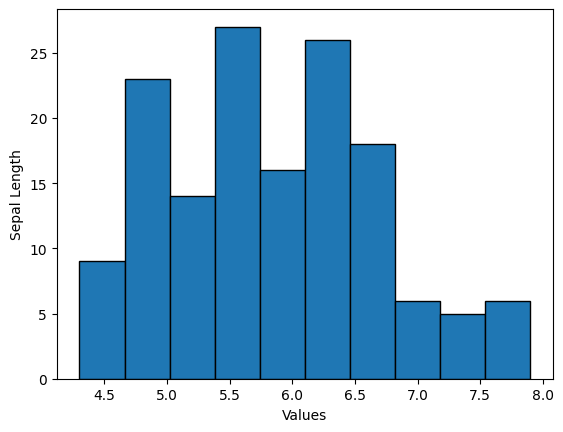

In [10]:
plt.hist(df["SepalLengthCm"], edgecolor = "black")
plt.ylabel("Sepal Length")
plt.xlabel("Values")

## (g) Create a boxplot to show the distribution of values for each attribute in the Iris dataset.

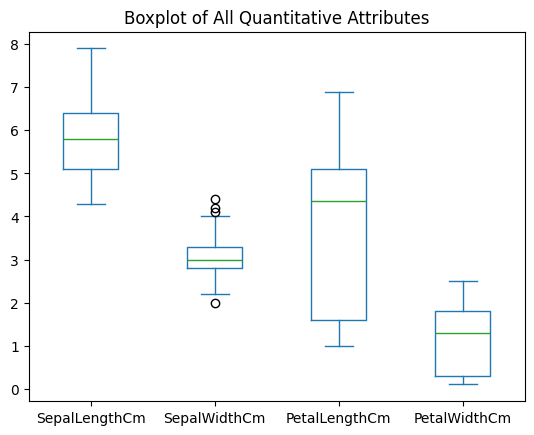

In [11]:
def boxplot_all(df, cols):
    df[cols].plot(kind='box')
    plt.title("Boxplot of All Quantitative Attributes")
    plt.show()

boxplot_all(df, quant_cols)


## (h) Create scatter plots to visualize the joint distribution of each pair of attributes in the Iris dataset

In [ ]:
def scatter_atrix(df, cols):
    pd.plotting.scatter_matrix(df[cols], figsize=(8, 8), diagonal='hist', marker = ['x', 'o', 'x', 'o'])
    plt.show()

# scatter_atrix(df, quant_cols)

def scatter_matrix_modified(df, cols, class_col):
    from pandas.plotting import scatter_matrix
    scatter_matrix(df[cols], c=df[class_col].astype('category').cat.codes, 
                   marker=['o','s','x'][0], figsize=(8,8))
    plt.show()

scatter_matrix_modified(df, k)

NameError: name 'kk' is not defined

## (i) Use parallel coordinates to display all the data points simultaneously in the Iris dataset.

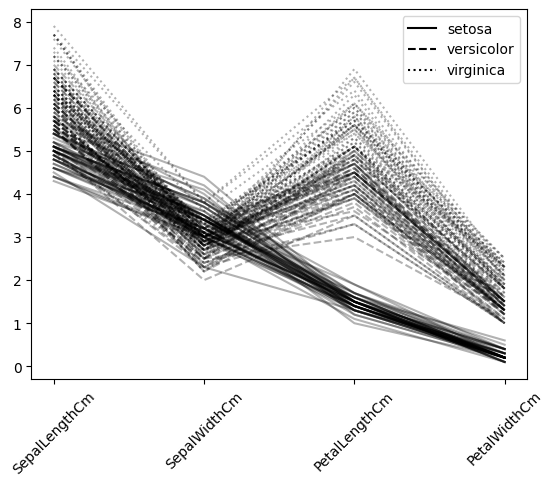

In [41]:
# def plot_parallel(df, cols, class_col):
#     parallel_coordinates(df[[*cols, class_col]], class_col)
#     plt.title("Parallel Coordinates of Iris Data")
#     plt.show()

def plot_parallel(df, cols, class_col):
    styles = ['-', '--', ':']
    species = df[class_col].unique()
    
    for i, sp in enumerate(species):
        plt.plot(df[df[class_col] == sp][cols].T, styles[i], alpha=0.3, color='black')
    
    plt.xticks(range(len(cols)), cols, rotation=45)
    plt.legend([plt.Line2D([0], [0], color='black', linestyle=s) for s in styles], species)
    plt.show()


plot_parallel(df, quant_cols, "Species")
